<a href="https://colab.research.google.com/github/slimani-meriem/camvid-unet-segmentation/blob/main/02_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
from google.colab import drive
drive.mount('/content/drive')

drive_root = '/content/drive/MyDrive/projets/camvid-unet-segmentation'
os.makedirs(f'{drive_root}/checkpoints', exist_ok=True)
os.makedirs(f'{drive_root}/results', exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from google.colab import userdata

token = userdata.get('GITHUB_TOKEN')
REPO = 'camvid-unet-segmentation'
repo_dir = f'/content/{REPO}'

if not os.path.exists(repo_dir):
    !git clone -q https://{token}@github.com/slimani-meriem/{REPO}.git {repo_dir}
else:
    !git -C {repo_dir} pull -q

%cd {repo_dir}
!ls src

/content/camvid-unet-segmentation
dataset.py  evaluate.py  __init__.py  metrics.py  model.py  train.py


In [5]:
!pip install -q -e .
!pip install -q segmentation-models-pytorch timm

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for camvid-segmentation (pyproject.toml) ... done


In [7]:
!pip install -q --upgrade kaggle

import os
from getpass import getpass

token = getpass("Kaggle token : ")
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
path = os.path.expanduser("~/.kaggle/access_token")
with open(path, "w") as f:
    f.write(token)
os.chmod(path, 0o600)

Kaggle token : ··········


In [8]:
!kaggle datasets download -d carlolepelaars/camvid
!unzip -q camvid.zip -d data/

Dataset URL: https://www.kaggle.com/datasets/carlolepelaars/camvid
License(s): CC-BY-NC-SA-4.0
100% 575M/575M [00:34<00:00, 17.5MB/s]



In [10]:
# little test
import torch
from src.dataset import get_dataloaders
from src.model import build_model, count_params

splits = {"train": ("train", "train_labels"),
          "val":   ("val",   "val_labels"),
          "test":  ("test",  "test_labels")}
loaders, mapper = get_dataloaders("data/CamVid", splits, batch_size=8)

model = build_model(mapper.num_classes).cuda()
img, mask = next(iter(loaders["train"]))
with torch.no_grad():
    logits = model(img.cuda())

print(logits.shape)                          # attendu : torch.Size([8, 31, 352, 480])
print(f"{count_params(model)[0] / 1e6:.1f} M parameters")   # de l'ordre de 24 M

/usr/local/lib/python3.13/dist-packages/segmentation_models_pytorch/encoders/__init__.py:86: UserWarning: For 'tu-' (timm universal) encoders, `encoder_weights` should be set to True to download pretrained weights or None for random initialization. The pretrained variant is defined in the encoder name i.e 'tu-<model_name>.<pretrained_tag>'. Got encoder_weights='imagenet'.
  warnings.warn(


torch.Size([8, 31, 352, 480])
24.4 M parameters


In [11]:
# launch a little training
!python -m src.train --data-dir data/CamVid --epochs 2 --freeze-epochs 1 \
  --ckpt-dir {drive_root}/checkpoints --results-dir {drive_root}/results \
  --run-name launch_test

device=cuda | amp=True | run=launch_test
31 classes | train: 369 images | val: 100 images | test: 232 images
/usr/local/lib/python3.13/dist-packages/segmentation_models_pytorch/encoders/__init__.py:86: UserWarning: For 'tu-' (timm universal) encoders, `encoder_weights` should be set to True to download pretrained weights or None for random initialization. The pretrained variant is defined in the encoder name i.e 'tu-<model_name>.<pretrained_tag>'. Got encoder_weights='imagenet'.
  warnings.warn(
encoder=tu-resnet34.a1_in1k | 24.4 M parameters
epoch   1/2 [frozen] loss 1.6496 | val mIoU 0.1506 mDice 0.1730 acc 0.8231 | 23s *
--> encoder unfrozen (24.4 M trainable parameters)
epoch   2/2          loss 0.7450 | val mIoU 0.1743 mDice 0.2026 acc 0.8470 | 25s *
done. best val mIoU = 0.1743 -> /content/drive/MyDrive/projets/camvid-unet-segmentation/checkpoints/launch_test_best.pth


In [12]:
# Tarin with 30 epochs
!python -m src.train --data-dir data/CamVid --epochs 30 --freeze-epochs 5 \
  --ckpt-dir {drive_root}/checkpoints --results-dir {drive_root}/results

device=cuda | amp=True | run=unet_resnet34
31 classes | train: 369 images | val: 100 images | test: 232 images
/usr/local/lib/python3.13/dist-packages/segmentation_models_pytorch/encoders/__init__.py:86: UserWarning: For 'tu-' (timm universal) encoders, `encoder_weights` should be set to True to download pretrained weights or None for random initialization. The pretrained variant is defined in the encoder name i.e 'tu-<model_name>.<pretrained_tag>'. Got encoder_weights='imagenet'.
  warnings.warn(
encoder=tu-resnet34.a1_in1k | 24.4 M parameters
epoch   1/30 [frozen] loss 1.6496 | val mIoU 0.1506 mDice 0.1730 acc 0.8231 | 22s *
epoch   2/30 [frozen] loss 0.6677 | val mIoU 0.1762 mDice 0.2042 acc 0.8448 | 24s *
epoch   3/30 [frozen] loss 0.5337 | val mIoU 0.2160 mDice 0.2556 acc 0.8661 | 24s *
epoch   4/30 [frozen] loss 0.4756 | val mIoU 0.2229 mDice 0.2662 acc 0.8648 | 24s *
epoch   5/30 [frozen] loss 0.4319 | val mIoU 0.2430 mDice 0.2953 acc 0.8793 | 25s *
--> encoder unfrozen (24.4 M 

best val mIoU (31 classes) : 0.4129


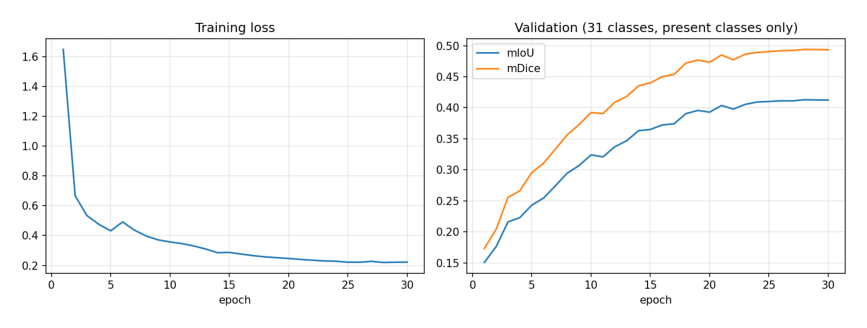

In [13]:
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

res = f'{drive_root}/results'
h = json.load(open(f'{res}/unet_resnet34_history.json'))
print(f"best val mIoU (31 classes) : {h['best_val_miou']:.4f}")

img = mpimg.imread(f'{res}/unet_resnet34_curves.png')
plt.figure(figsize=(11, 4))
plt.imshow(img)
plt.axis('off')
plt.show()